# Linear static analysis of a plate

A simply supported plate of `Quad4` elements under a central point
load. The maximum of the normal displacement $w$ is compared with the series
solution of Timoshenko, S. and Woinowsky-Krieger, S., Theory of Plates and
Shells, 2nd ed., McGraw-Hill, 1959, Art. 34.

In [1]:
import os
import sys

sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import cg
from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import isotropic_plate

The steps are those of [Overview and workflow](../overview.rst): the nodes,
the property of an isotropic plate, the elements with their positions
`c1, ..., c4` and `init_k_KC0`, the assembly of `KC0` with
`scipy.sparse.coo_matrix`, the boundary conditions as the Boolean arrays `bk`
and `bu`, the solution of the free dofs and, at the end, the internal force
vector of `update_fint`, which balances the load and the support reactions.
The function below is `tests/test_quad4_static_point_load.py`:

In [2]:
def test_static_plate_quad_point_load(plot=False):
    r"""Simply supported rectangular plate, ``a = 3``, ``b = 7``,
    ``h = 0.005``, under a point load at its centre

    The reference is the Navier solution of Timoshenko, S., and
    Woinowsky-Krieger, S., Theory of Plates and Shells, 2nd ed., McGraw-Hill,
    1959, Art. 29, p. 111, Eq. (133), at the centre, summed in Art. 34,
    p. 143, as the single series of Eq. (147),
    ``w_max = alpha*P*a**2/D``, with
    ``alpha = sum((tanh(alpha_m) - alpha_m/cosh(alpha_m)**2)/m**3)/(2*pi**3)``
    over ``m = 1, 3, 5, ...`` and ``alpha_m = m*pi*b/(2*a)``. For
    ``b/a = 7/3``, ``alpha = 0.016785``, between the values 0.01651 and
    0.01690 of their Table 23 for ``b/a = 2`` and 3. Truncating the series
    at ``m = 79`` changes it by less than 1e-4.

    This is the Kirchhoff plate. The transverse shear deflection of the
    Mindlin plate under a point load is logarithmically singular, the shear
    part of its Navier series being
    ``4*P/(pi**2*a*b*A55)*sum(1/((m/a)**2 + (n/b)**2))``, but with
    ``a/h = 600`` it is small: truncated at the wavenumbers that the meshes
    below resolve, ``m < 2*(nx - 1)`` and ``n < 2*(ny - 1)``, it adds
    2.0e-5 to 3.6e-5 of the reference deflection.

    With 18x30 elements the deflection at the centre is 0.24 % below the
    reference, with 6x10 elements 1.54 %, with 12x20 elements 0.49 %, with
    24x40 elements 0.13 %.
    """
    data = Quad4Data()
    probe = Quad4Probe()
    nx = 19
    ny = 31

    a = 3
    b = 7
    h = 0.005 # m

    E = 200e9
    nu = 0.3

    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(), np.zeros_like(ymesh.T.flatten()))).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    z = ncoords[:, 2]
    ncoords_flatten = ncoords.flatten()

    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()

    num_elements = len(n1s)

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    N = DOF*nx*ny

    prop = isotropic_plate(thickness=h, E=E, nu=nu)

    quads = []
    init_k_KC0 = 0
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        pos1 = nid_pos[n1]
        pos2 = nid_pos[n2]
        pos3 = nid_pos[n3]
        pos4 = nid_pos[n4]
        r1 = ncoords[pos1]
        r2 = ncoords[pos2]
        r3 = ncoords[pos3]
        normal = np.cross(r2 - r1, r3 - r2)[2]
        assert normal > 0
        quad = Quad4(probe)
        quad.n1 = n1
        quad.n2 = n2
        quad.n3 = n3
        quad.n4 = n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = init_k_KC0
        quad.K6ROT = 100.
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quads.append(quad)
        init_k_KC0 += data.KC0_SPARSE_SIZE

    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    print('elements created')

    bk = np.zeros(N, dtype=bool)
    check = np.isclose(x, 0.) | np.isclose(x, a) | np.isclose(y, 0) | np.isclose(y, b)
    bk[2::DOF] = check

    bk[0::DOF] = True
    bk[1::DOF] = True

    bu = ~bk

    # point load at center node
    fext = np.zeros(N)
    fmid = 1.
    check = np.isclose(x, a/2) & np.isclose(y, b/2)
    fext[2::DOF][check] = fmid

    KC0uu = KC0[bu, :][:, bu]
    assert fext[bu].sum() == fmid

    uu, info = cg(KC0uu, fext[bu], atol=1e-9)
    assert info == 0

    u = np.zeros(N)
    u[bu] = uu

    w = u[2::DOF].reshape(nx, ny).T

    # NOTE Timoshenko and Woinowsky-Krieger (1959), Eq. (147)
    D = E*h**3/(12*(1 - nu**2))
    m = np.arange(1, 80, 2)
    alpha_m = m*np.pi*b/(2*a)
    alpha = np.sum((np.tanh(alpha_m) - alpha_m/np.cosh(alpha_m)**2)/m**3)/(2*np.pi**3)
    wmax_ref = alpha*fmid*a**2/D
    print('alpha', alpha)
    print('wmax_ref', wmax_ref)
    print('w.max()', w.max())
    assert np.isclose(wmax_ref, w.max(), rtol=0.01)

    fint = np.zeros(N)
    for quad in quads:
        quad.update_probe_xe(ncoords_flatten)
        quad.update_probe_ue(u)
        quad.update_fint(fint, prop)

    # NOTE adding reaction forces to external force vector
    Kku = KC0[bk, :][:, bu]
    fext[bk] = Kku @ u[bu]
    atol = 1e-5
    tmp = np.where(np.logical_not(np.isclose(fint, fext, atol=atol)))
    print(tmp)
    print(fint[tmp[0]])
    print(fext[tmp[0]])
    print((KC0@u)[tmp[0]])
    assert np.allclose(fint, fext, atol=atol)

    if plot:
        import matplotlib.pyplot as plt

        plt.gca().set_aspect('equal')
        levels = np.linspace(w.min(), w.max(), 10)
        plt.contourf(xmesh, ymesh, w, levels=levels)
        plt.colorbar()
        plt.show()

With `plot=True` the test plots the normal displacement $w$:

elements created


alpha 0.016784601471528153
wmax_ref 6.598362530487146e-05
w.max() 6.575388331113805e-05
(array([], dtype=int64),)
[]
[]
[]


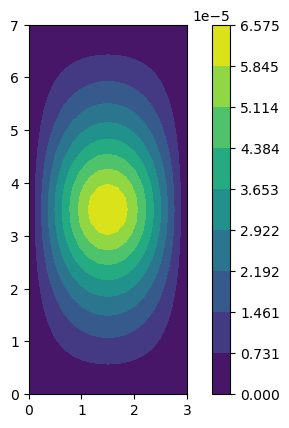

In [3]:
test_static_plate_quad_point_load(plot=True)